<a href="https://colab.research.google.com/github/Temmy-bit/computer-vision-lab/blob/main/Deep_Dream.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
tf.__version__

'2.19.0'

In [ ]:
base_model = tf.keras.applications.InceptionV3(include_top=False, weights='imagenet')

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
base_model.summary()

Model: "inception_v3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, None,      │          0 │ -                 │
│ (InputLayer)        │ None, 3)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, None,      │        864 │ input_layer[0][0] │
│                     │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, None,      │         96 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, None,      │          0 │ batch_normalizat… │
│ (Activation)        │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, None,      │      9,216 │ activation[0][0]  │
│                     │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, None,      │         96 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, None,      │          0 │ batch_normalizat… │
│ (Activation)        │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, None,      │     18,432 │ activation_1[0][… │
│                     │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, None,      │        192 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, None,      │          0 │ batch_normalizat… │
│ (Activation)        │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, None,      │          0 │ activation_2[0][… │
│ (MaxPooling2D)      │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, None,      │      5,120 │ max_pooling2d[0]… │
│                     │ None, 80)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, None,      │        240 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ None, 80)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, None,      │          0 │ batch_normalizat… │
│ (Activation)        │ None, 80)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, None,      │    138,240 │ activation_3[0][… │
│                     │ None, 192)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, None,      │        576 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ None, 192)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, None,      │          0 │ batch_normalizat

 Total params: 21,802,784 (83.17 MB)

 Trainable params: 21,768,352 (83.04 MB)

 Non-trainable params: 34,432 (134.50 KB)

In [ ]:
len(base_model.layers)

311

In [ ]:
names = ['mixed3','mixed5', 'mixed8','mixed9']
# names = ['mixed3','mixed5']

In [ ]:
base_model.input

<KerasTensor shape=(None, None, None, 3), dtype=float32, sparse=False, ragged=False, name=keras_tensor>

In [ ]:
layers = [base_model.get_layer(name).output for name in names]

In [ ]:
layers

[<KerasTensor shape=(None, None, None, 768), dtype=float32, sparse=False, ragged=False, name=keras_tensor_100>,
 <KerasTensor shape=(None, None, None, 768), dtype=float32, sparse=False, ragged=False, name=keras_tensor_164>,
 <KerasTensor shape=(None, None, None, 1280), dtype=float32, sparse=False, ragged=False, name=keras_tensor_248>,
 <KerasTensor shape=(None, None, None, 2048), dtype=float32, sparse=False, ragged=False, name=keras_tensor_279>]

In [ ]:
deep_dream = tf.keras.Model(inputs=base_model.input, outputs=[base_model.get_layer(name).output for name in names])

Loading And Pre-Processing The Image

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
image = tf.keras.preprocessing.image.load_img('/content/drive/MyDrive/Computer Vision Masterclass/Images/StaryNight.jpg',target_size=(225,375))

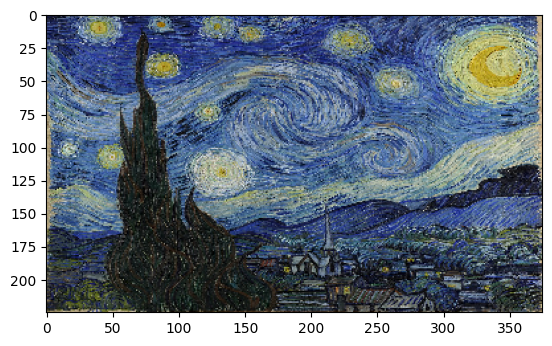

In [ ]:
plt.imshow(image);

In [ ]:
type(image)

PIL.Image.Image

In [ ]:
image.size

(375, 225)

In [ ]:
image.mode, len(image.mode)

('RGB', 3)

In [ ]:
# list(image.getdata())

In [ ]:
image = tf.keras.preprocessing.image.img_to_array(image)

In [ ]:
type(image)

numpy.ndarray

In [ ]:
image.shape

(225, 375, 3)

In [ ]:
image.min(),image.max()

(np.float32(0.0), np.float32(255.0))

In [ ]:
# image /= 255.
image = tf.keras.applications.inception_v3.preprocess_input(image)

In [ ]:
image.min(), image.max()

(np.float32(-1.0), np.float32(1.0))

Getting The Activation

In [ ]:
image_batch = tf.expand_dims(image,axis=0)

In [ ]:
image_batch.shape

TensorShape([1, 225, 375, 3])

In [ ]:
activations = deep_dream.predict(image_batch)

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


In [ ]:
deep_dream.outputs

[<KerasTensor shape=(None, None, None, 768), dtype=float32, sparse=False, ragged=False, name=keras_tensor_100>,
 <KerasTensor shape=(None, None, None, 768), dtype=float32, sparse=False, ragged=False, name=keras_tensor_164>,
 <KerasTensor shape=(None, None, None, 1280), dtype=float32, sparse=False, ragged=False, name=keras_tensor_248>,
 <KerasTensor shape=(None, None, None, 2048), dtype=float32, sparse=False, ragged=False, name=keras_tensor_279>]

In [ ]:
len(activations)

4

In [ ]:
activations[1].shape, activations[0].shape

((1, 12, 21, 768), (1, 12, 21, 768))

Calculating The Loss

In [ ]:
def calculate_loss(image, network):
  image_batch = tf.expand_dims(image,axis=0)
  activations = network(image_batch)

  losses = []
  for act in activations:
    loss = tf.math.reduce_mean(act)
    losses.append(loss)

  # print(losses)
  # print(np.shape(losses))
  # print(tf.reduce_sum(losses))
  return tf.reduce_sum(losses)

In [ ]:
loss = calculate_loss(image, deep_dream)
loss

<tf.Tensor: shape=(), dtype=float32, numpy=0.8365874290466309>

Gradient Ascent

In [ ]:
@tf.function
def dee_dream(network, image, learning_rate):
  with tf.GradientTape() as tape:
    tape.watch(image)
    loss = calculate_loss(image, network)

  gradients = tape.gradient(loss, image) # Derivative
  gradients /= tf.math.reduce_std(gradients)
  image = image + gradients * learning_rate
  image = tf.clip_by_value(image, -1, 1)
  return loss, image

In [ ]:
def inverse_transform(image):
  image = 255 * (image + 1.0)/2.0
  return tf.cast(image, tf.uint8)

In [ ]:
def run_deep_dream(network, image, epochs=10, learning_rate=0.01):
  for epoch in range(epochs):
    loss, image = dee_dream(network, image, learning_rate)
    if epoch % 100 == 0:
      plt.figure(figsize=(12,12))
      plt.imshow(inverse_transform(image))
      plt.show()
      print(f'Epoch: {epoch}, Loss: {loss}')


Generate Images

In [ ]:
image.shape,type(image)

((225, 375, 3), numpy.ndarray)

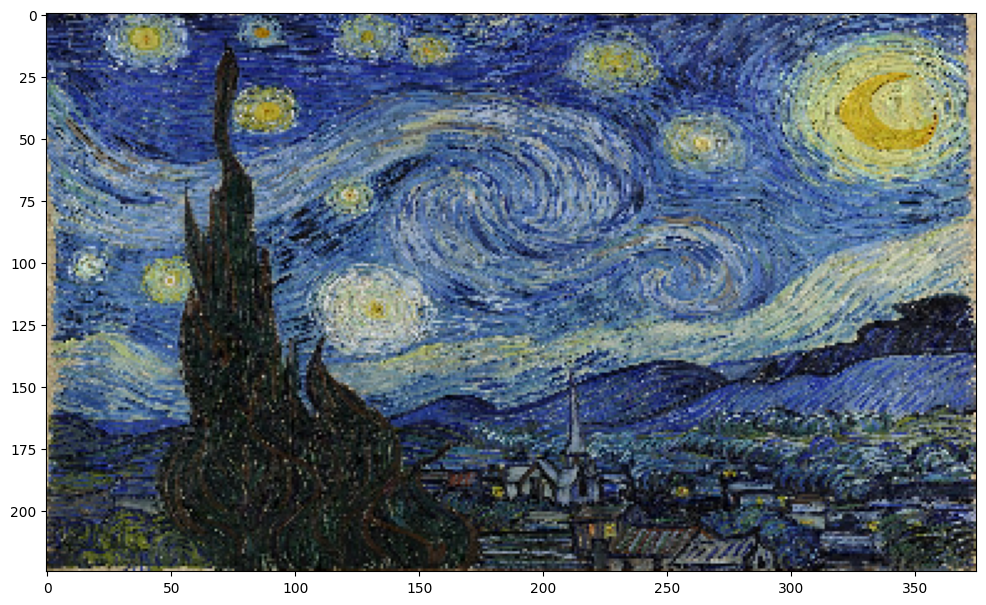

Epoch: 0, Loss: 0.8365874290466309


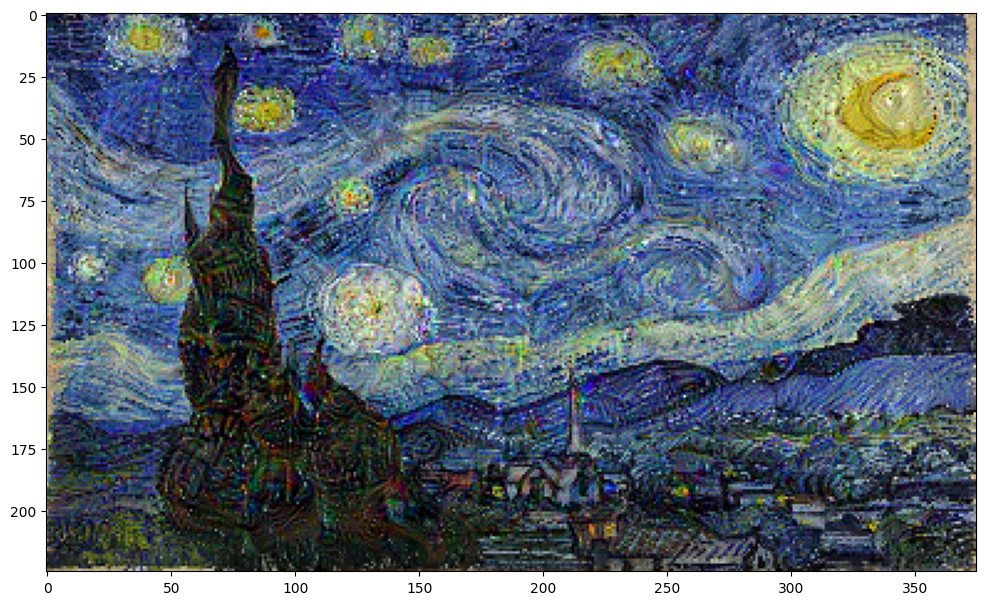

Epoch: 100, Loss: 2.959040641784668


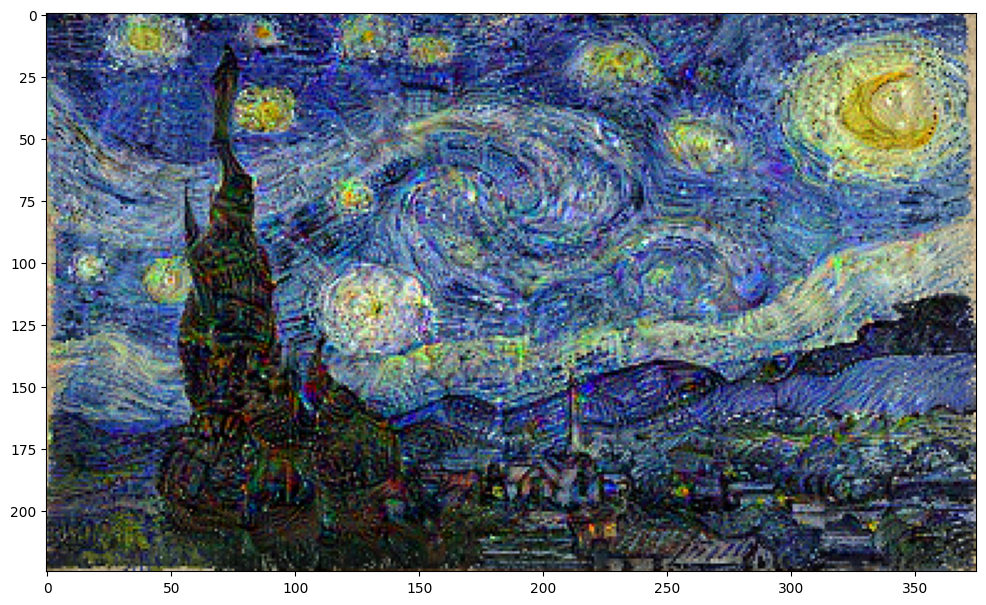

Epoch: 200, Loss: 3.6703455448150635


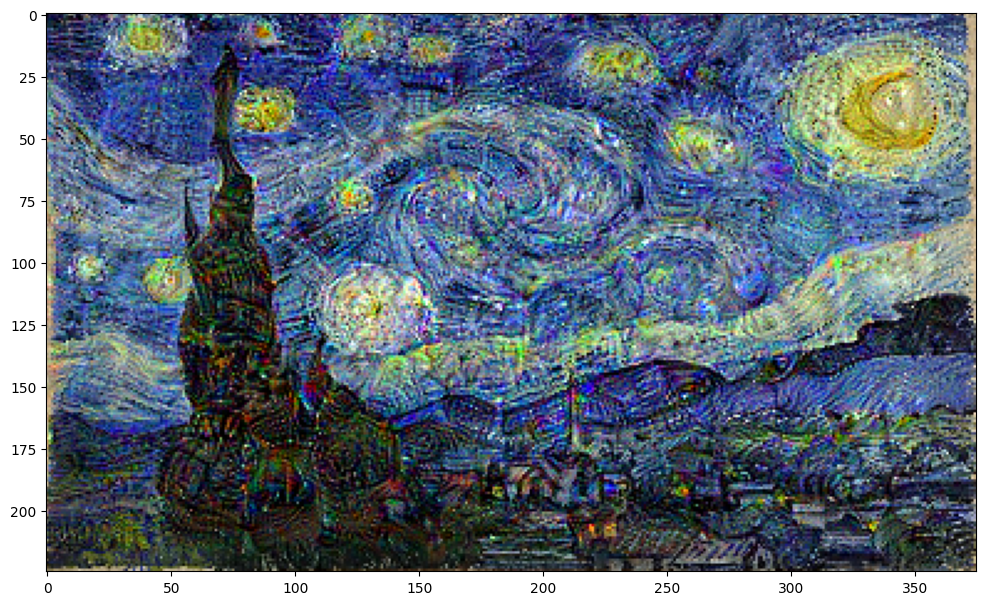

Epoch: 300, Loss: 4.073256969451904


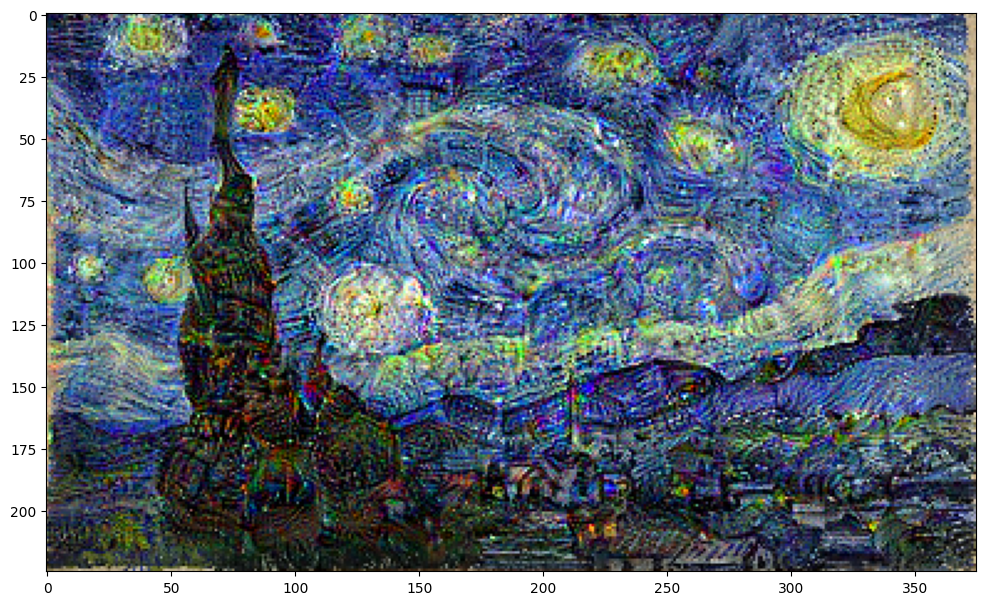

Epoch: 400, Loss: 4.393691062927246


In [ ]:
run_deep_dream(deep_dream, image, epochs=500, learning_rate=0.01)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 714ms/step


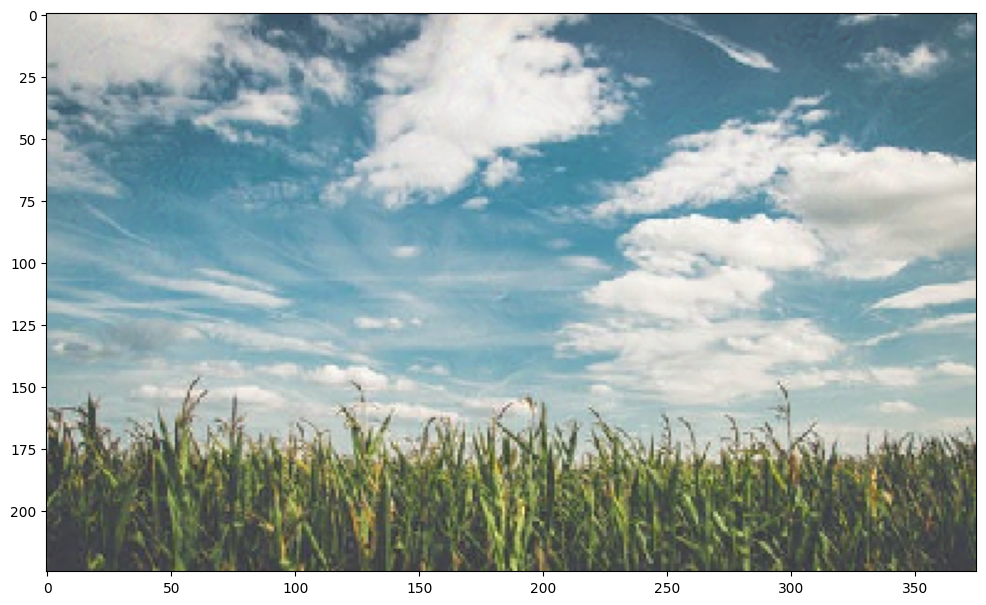

Epoch: 0, Loss: 0.8320485353469849


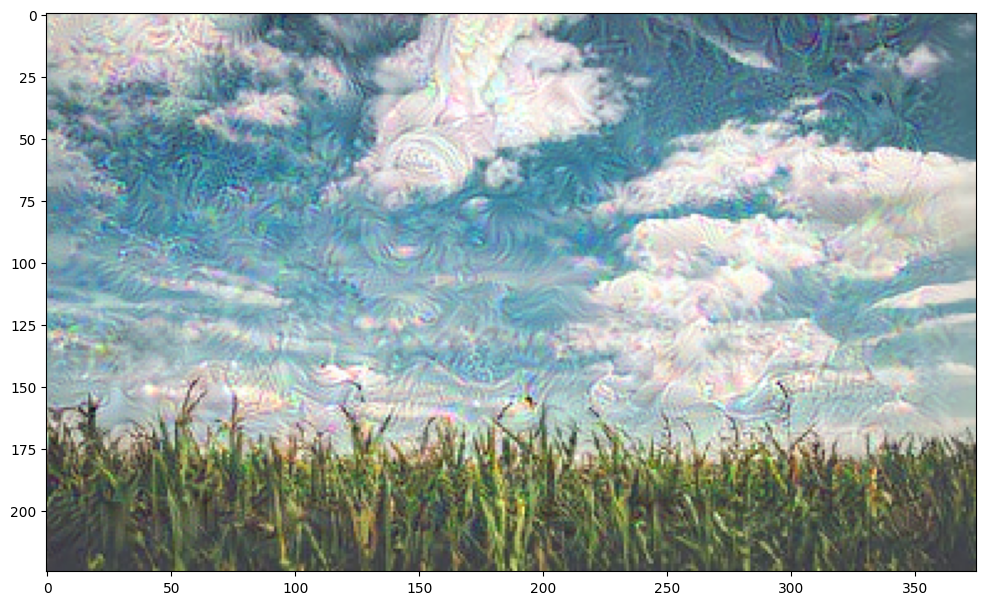

Epoch: 100, Loss: 2.872018337249756


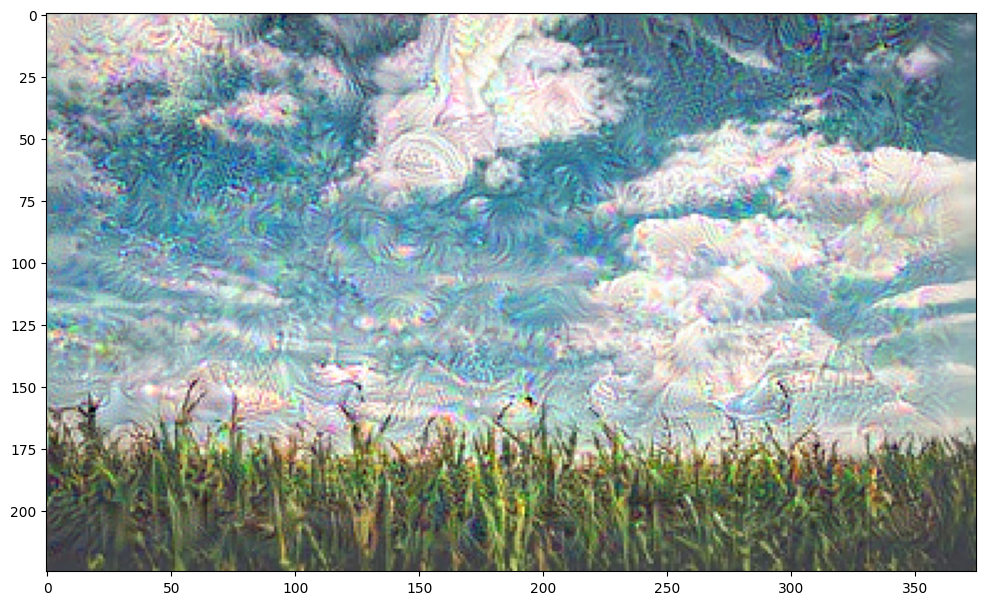

Epoch: 200, Loss: 3.3607571125030518


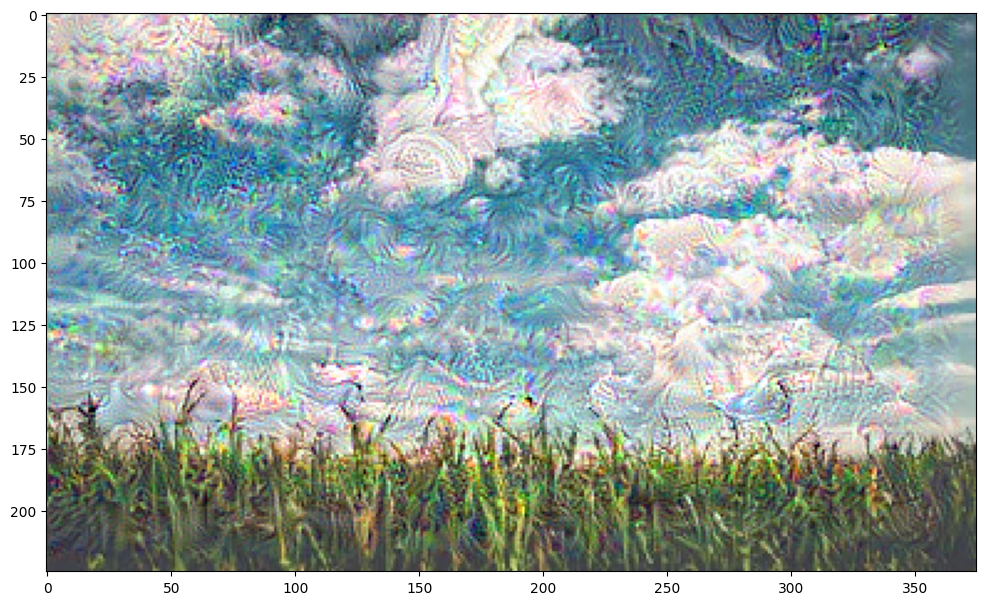

Epoch: 300, Loss: 3.672240734100342


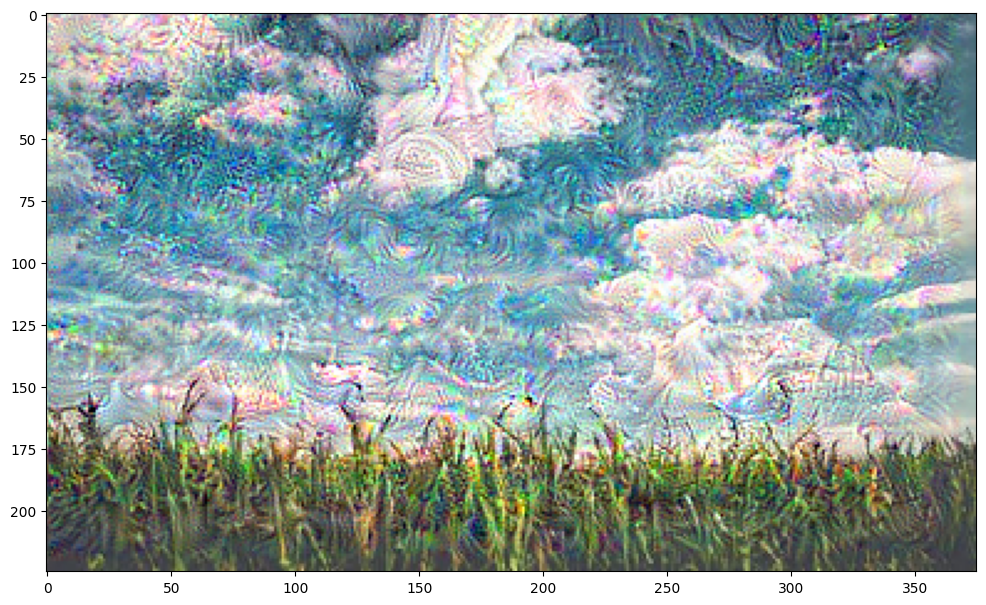

Epoch: 400, Loss: 3.896667242050171


In [ ]:
image = tf.keras.preprocessing.image.load_img('/content/drive/MyDrive/Computer Vision Masterclass/Images/sky.jpeg',target_size=(225,375))
image = tf.keras.preprocessing.image.img_to_array(image)
# image /= 255.
image = tf.keras.applications.inception_v3.preprocess_input(image)
image_batch = tf.expand_dims(image,axis=0)
activations = deep_dream.predict(image_batch)
run_deep_dream(deep_dream, image, epochs=500, learning_rate=0.01)